In [ ]:
###  Model Training, MLOps & Evaluation ---

In [ ]:
### Enviroment

In [ ]:
import os
import json
import math
import random
import shutil
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from torch.utils.data import (Dataset,DataLoader,WeightedRandomSampler)

from sklearn.metrics import (
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve,
    roc_curve,
    average_precision_score
)

from sklearn.calibration import calibration_curve

warnings.filterwarnings("ignore")

print("PyTorch version:", torch.__version__)
print("CUDA available :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA:", torch.version.cuda)

PyTorch version: 2.11.0+cu128
CUDA available : True
GPU: Tesla T4
CUDA: 12.8


In [ ]:
### Connect google drive

In [ ]:
from google.colab import drive

drive.mount("/content/drive")
BASE_DIR = "/content/drive/MyDrive/Nexlyra/11-09-26-Ravi"

TENSOR_DIR = os.path.join(BASE_DIR,"tensors")
MODEL_DIR = os.path.join(BASE_DIR,"models")
EVALUATION_DIR = os.path.join(BASE_DIR,"evaluation")
TRAINING_DIR = os.path.join(BASE_DIR,"training")
REPORT_DIR = os.path.join(BASE_DIR,"reports")
BACKUP_DIR = os.path.join(BASE_DIR,"backup")

for directory in [TENSOR_DIR,MODEL_DIR,EVALUATION_DIR,TRAINING_DIR,REPORT_DIR,BACKUP_DIR]:
    os.makedirs(directory,exist_ok=True)

print("Base directory:")
print(BASE_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Base directory:
/content/drive/MyDrive/Nexlyra/11-09-26-Ravi


In [ ]:
### Reproducibility

In [ ]:
RANDOM_STATE = 42

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

torch.backends.cudnn.deterministic = False
torch.backends.cudnn.benchmark = True

print("Random seed:", RANDOM_STATE)

Random seed: 42


In [ ]:
### DEVICE CONFIGURATION

In [ ]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_ENABLED = DEVICE.type == "cuda"

print("Device:", DEVICE)
print("AMP enabled:", AMP_ENABLED)

if DEVICE.type == "cuda":
    print("GPU count:",torch.cuda.device_count())

Device: cuda
AMP enabled: True
GPU count: 1


In [ ]:
### LOAD TENSOR

In [ ]:
TRAIN_FILE = os.path.join(TENSOR_DIR,"final_train_dual_input.pt")
VAL_FILE = os.path.join(TENSOR_DIR,"final_val_dual_input.pt")
TEST_FILE = os.path.join(TENSOR_DIR,"final_test_dual_input.pt")

assert os.path.exists(TRAIN_FILE), (f"Missing: {TRAIN_FILE}")
assert os.path.exists(VAL_FILE), (f"Missing: {VAL_FILE}")
assert os.path.exists(TEST_FILE), (f"Missing: {TEST_FILE}")

train_data = torch.load(TRAIN_FILE,map_location="cpu")
val_data = torch.load(VAL_FILE, map_location="cpu")
test_data = torch.load(TEST_FILE,map_location="cpu")

print("tensors loaded successfully.")

tensors loaded successfully.


In [ ]:
### DATASET INTEGERITY VALIDATION

In [ ]:
def validate_tensor_dataset(data,name):

    strain = data["strain"]
    features = data["features"]
    target = data["target"]

    print(f"\n{name}")
    print("-" * 50)

    print("Strain shape   :", strain.shape)
    print("Features shape :", features.shape)
    print("Target shape   :", target.shape)

    assert strain.ndim == 4
    assert strain.shape[1:] == (1, 8, 8)

    assert features.ndim == 2
    assert features.shape[1] == 5

    assert target.ndim == 1

    assert len(strain) == len(features)
    assert len(features) == len(target)

    assert strain.dtype == torch.float32
    assert features.dtype == torch.float32

    assert torch.isfinite(strain).all()
    assert torch.isfinite(features).all()
    assert torch.isfinite(target).all()

    unique_targets = torch.unique(target)

    assert set(unique_targets.tolist()).issubset({0.0, 1.0})

    print("Data integrity : PASS")
    print("Positive count :",int((target == 1).sum()))
    print("Negative count :",int((target == 0).sum()))


validate_tensor_dataset(train_data,"TRAIN")
validate_tensor_dataset(val_data,"VALIDATION")
validate_tensor_dataset(test_data,"TEST")


TRAIN
--------------------------------------------------
Strain shape   : torch.Size([747583, 1, 8, 8])
Features shape : torch.Size([747583, 5])
Target shape   : torch.Size([747583])
Data integrity : PASS
Positive count : 95166
Negative count : 652417

VALIDATION
--------------------------------------------------
Strain shape   : torch.Size([150000, 1, 8, 8])
Features shape : torch.Size([150000, 5])
Target shape   : torch.Size([150000])
Data integrity : PASS
Positive count : 10197
Negative count : 139803

TEST
--------------------------------------------------
Strain shape   : torch.Size([150000, 1, 8, 8])
Features shape : torch.Size([150000, 5])
Target shape   : torch.Size([150000])
Data integrity : PASS
Positive count : 10196
Negative count : 139804


In [ ]:
### DATASET CLASS

In [ ]:
class StrainVisionDataset(Dataset):

    def __init__(self, data):
        self.strain = data["strain"]
        self.features = data["features"]
        self.target = data["target"]

    def __len__(self):
        return len(self.target)

    def __getitem__(self, index):

        return (
            self.strain[index].float(),
            self.features[index].float(),
            self.target[index].float()
        )

In [ ]:
### WEIGHT RANDOM SAMPLER

In [ ]:
train_targets = train_data["target"].long()
class_counts = torch.bincount(train_targets,minlength=2)

negative_count = class_counts[0].item()
positive_count = class_counts[1].item()

class_weights = torch.tensor([1.0 / negative_count,1.0 / positive_count],dtype=torch.float32)
sample_weights = (class_weights[train_targets])
train_sampler = WeightedRandomSampler(weights=sample_weights,num_samples=len(train_targets),replacement=True)

print("Negative:", negative_count)
print("Positive:", positive_count)

print("Negative class weight:",class_weights[0].item())
print("Positive class weight:",class_weights[1].item())

Negative: 652417
Positive: 95166
Negative class weight: 1.532761984890385e-06
Positive class weight: 1.0507954357308336e-05


In [ ]:
### DATA LOADER

In [ ]:
BATCH_SIZE = 256
NUM_WORKERS = 2
PIN_MEMORY = (DEVICE.type == "cuda")

train_dataset = StrainVisionDataset(train_data)
val_dataset = StrainVisionDataset(val_data)
test_dataset = StrainVisionDataset(test_data)

train_loader = DataLoader(train_dataset,
                          batch_size=BATCH_SIZE,
                          sampler=train_sampler,
                          num_workers=NUM_WORKERS,
                          pin_memory=PIN_MEMORY,
                          persistent_workers=(NUM_WORKERS > 0))

val_loader = DataLoader(val_dataset,
                        batch_size=BATCH_SIZE,
                        shuffle=False,
                        num_workers=NUM_WORKERS,
                        pin_memory=PIN_MEMORY,
                        persistent_workers=(NUM_WORKERS > 0))

test_loader = DataLoader(test_dataset,
                         batch_size=BATCH_SIZE,
                         shuffle=False,
                         num_workers=NUM_WORKERS,
                         pin_memory=PIN_MEMORY,
                         persistent_workers=(NUM_WORKERS > 0))

print("Train batches:", len(train_loader))
print("Val batches  :", len(val_loader))
print("Test batches :", len(test_loader))

Train batches: 2921
Val batches  : 586
Test batches : 586


In [ ]:
### FINAL CNN ARCHITECTURE

In [ ]:
class StrainVisionNet(nn.Module):

    def __init__(self,tabular_dim=5):
        super().__init__()

        # Spatial CNN Branch
        self.spatial_branch = nn.Sequential(nn.Conv2d(in_channels=1,out_channels=32,kernel_size=3,padding=1),
                              nn.BatchNorm2d(32),
                              nn.LeakyReLU(inplace=True),
                              nn.Conv2d(in_channels=32,out_channels=64,kernel_size=3,padding=1),
                              nn.MaxPool2d(kernel_size=2,stride=2),
                              nn.Flatten())


        # Tabular MLP Branch
        self.tabular_branch = nn.Sequential(nn.Linear(tabular_dim,64),
                              nn.ReLU(inplace=True),
                              nn.Dropout(p=0.4),
                              nn.Linear(64,32),
                              nn.ReLU(inplace=True),
                              nn.Dropout(p=0.4))

        # Fusion
        self.fusion = nn.Sequential(nn.Linear(1024 + 32,128),
                      nn.ReLU(inplace=True),
                      nn.Dropout(p=0.4),
                      nn.Linear(128,1))

    def forward(self,spatial_x,tabular_x):
        spatial_features = (self.spatial_branch(spatial_x))
        tabular_features = (self.tabular_branch(tabular_x))

        combined_features = torch.cat([spatial_features,tabular_features],dim=1)
        logits = self.fusion(combined_features)

        return logits

In [ ]:
### KAIMING INITIALIZATION

In [ ]:
def initialize_cnn_weights(model):

    for module in model.modules():

        if isinstance(module,nn.Conv2d):
            nn.init.kaiming_uniform_( module.weight,
                                     mode="fan_in",
                                    nonlinearity="leaky_relu")

            if module.bias is not None:
              nn.init.zeros_(module.bias)

        elif isinstance(module,nn.BatchNorm2d):
            nn.init.ones_(module.weight)
            nn.init.zeros_(module.bias)


model = StrainVisionNet(tabular_dim=5)
initialize_cnn_weights(model)

print("Trainable parameters:",sum(p.numel() for p in model.parameters() if p.requires_grad))

Trainable parameters: 156769


In [ ]:
### DATA PARALLEL

In [ ]:
model = model.to(DEVICE)

if (DEVICE.type == "cuda" and torch.cuda.device_count() > 1):
    model = nn.DataParallel(model)
    print("Using DataParallel:",torch.cuda.device_count(),"GPUs")

else:
    print("Using single device:",DEVICE)

Using single device: cuda


In [ ]:
### DEVICE VERIFICATION

In [ ]:
def unwrap_model(model):
    if isinstance(model,nn.DataParallel):
        return model.module

    return model


def verify_devices(model,loader,device):

    model_device = next(model.parameters()).device
    spatial_x, tabular_x, target = next(iter(loader))

    spatial_x = spatial_x.to(device,non_blocking=True)
    tabular_x = tabular_x.to(device,non_blocking=True)
    target = target.to(device,non_blocking=True)

    model.eval()

    with torch.no_grad():
        output = model(spatial_x,tabular_x)

    print("Model device  :", model_device)
    print("Spatial device:",spatial_x.device)
    print("Feature device:",tabular_x.device)

    print("Target device :",target.device)
    print("Output device :",output.device)
    print("Output shape  :",output.shape)

    assert output.shape == (spatial_x.shape[0],1)

    print("\nPASS: Device verification successful.")

verify_devices(model,train_loader,DEVICE)

Model device  : cuda:0
Spatial device: cuda:0
Feature device: cuda:0
Target device : cuda:0
Output device : cuda:0
Output shape  : torch.Size([256, 1])

PASS: Device verification successful.


In [ ]:
### ASYMMETRIC FOCAL LOSS

In [ ]:
class AsymmetricFocalLoss(nn.Module):

    def __init__(self,alpha_neg=2.0,
                 alpha_pos=1.0,
                 gamma_neg=2.0,
                 gamma_pos=1.0):

        super().__init__()

        self.alpha_neg = alpha_neg
        self.alpha_pos = alpha_pos
        self.gamma_neg = gamma_neg
        self.gamma_pos = gamma_pos

    def forward(self,logits,targets):

        targets = (targets.float().view_as(logits))

        probabilities = torch.sigmoid(logits)
        p_pos = probabilities
        p_neg = 1.0 - probabilities

        positive_log_loss = (targets * torch.log(torch.clamp(p_pos,min=1e-8)))
        negative_log_loss = ((1.0 - targets) * torch.log(torch.clamp(p_neg,min=1e-8)))

        positive_focal = (1.0 - p_pos).pow(self.gamma_pos)
        negative_focal = (1.0 - p_neg).pow(self.gamma_neg)

        loss = (self.alpha_pos * positive_focal * positive_log_loss
            +self.alpha_neg * negative_focal * negative_log_loss)

        return -loss.mean()


criterion = AsymmetricFocalLoss(alpha_neg=2.0,alpha_pos=1.0,gamma_neg=2.0, gamma_pos=1.0)

In [ ]:
### OPTIMIZER + SCHEDULAR ---> (40 EPOCHS)

In [ ]:
LEARNING_RATE = 2e-4
WEIGHT_DECAY = 1e-4
EPOCHS = 40

optimizer = torch.optim.AdamW(model.parameters(),
                              lr=LEARNING_RATE,
                              weight_decay=WEIGHT_DECAY)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,
                                                       T_max=EPOCHS,
                                                       eta_min=1e-6)

print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Epochs:", EPOCHS)

Optimizer: AdamW
Learning rate: 0.0002
Weight decay: 0.0001
Epochs: 40


In [ ]:
### AMP SCALER

In [ ]:
scaler = torch.amp.GradScaler("cuda",enabled=AMP_ENABLED)
print("Mixed precision:",AMP_ENABLED)

Mixed precision: True


In [ ]:
### MIXUP

In [ ]:
def mixup_dual_input(strain_batch,features_batch,
                     target_batch,alpha=0.2,p=0.5):

    if torch.rand(1,device=strain_batch.device).item() > p:

        return (strain_batch,features_batch,target_batch,target_batch,
                torch.tensor(1.0,device=strain_batch.device))

    beta = torch.distributions.Beta(alpha,alpha)
    lam = beta.sample().to(strain_batch.device)

    permutation = torch.randperm(strain_batch.size(0),
                                device=strain_batch.device)

    mixed_strain = (lam * strain_batch + (1.0 - lam) * strain_batch[permutation])
    mixed_features = (lam * features_batch + (1.0 - lam) * features_batch[permutation])

    target_a = target_batch
    target_b = (target_batch[permutation])

    return (mixed_strain,mixed_features,
            target_a,target_b,lam)

In [ ]:
### PRODUCTION TRAINING FUNCTION

In [ ]:
def train_one_epoch(model,loader,optimizer,criterion,scaler,
                    device, mixup_alpha=0.2,mixup_probability=0.5,max_grad_norm=1.0):

    model.train()

    running_loss = 0.0
    total_samples = 0

    for (spatial_x,tabular_x,targets) in loader:

        spatial_x = spatial_x.to(device,non_blocking=True)
        tabular_x = tabular_x.to(device,non_blocking=True)
        targets = targets.to(device,non_blocking=True)

        (spatial_x,tabular_x,
        target_a,target_b,lam) = mixup_dual_input(spatial_x,tabular_x,targets,
                                                  alpha=mixup_alpha,p=mixup_probability)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(device_type="cuda",enabled=AMP_ENABLED):

            logits = model(spatial_x,tabular_x)
            target_a = (target_a.float().view_as(logits))
            target_b = (target_b.float().view_as(logits))

            loss_a = criterion(logits,target_a)
            loss_b = criterion(logits,target_b)

            loss = (lam * loss_a +(1.0 - lam) * loss_b)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(model.parameters(),max_norm=max_grad_norm)

        scaler.step(optimizer)
        scaler.update()

        batch_size = (spatial_x.size(0))
        running_loss += (loss.item() * batch_size)
        total_samples += (batch_size)

    return (running_loss/ total_samples)

In [ ]:
### VALIDATION FUNCTION

In [ ]:
def validate(model,loader,criterion,device,threshold=0.5):

    model.eval()

    running_loss = 0.0
    total_samples = 0

    all_targets = []
    all_probabilities = []

    with torch.no_grad():

        for (spatial_x,tabular_x,targets) in loader:

            spatial_x = spatial_x.to(device,non_blocking=True)
            tabular_x = tabular_x.to(device,non_blocking=True)
            targets = targets.to(device,non_blocking=True)

            with torch.amp.autocast(device_type="cuda",enabled=AMP_ENABLED ):

                logits = model(spatial_x,tabular_x)
                target_view = (targets.float().view_as(logits))
                loss = criterion(logits,target_view)

            probabilities = (torch.sigmoid(logits).squeeze(1))
            batch_size = (spatial_x.size(0))
            running_loss += (loss.item()* batch_size)
            total_samples += (batch_size)

            # IMPORTANT:
            # detach() -> cpu()
            # NOT device()
            all_targets.append(targets.detach().cpu())
            all_probabilities.append(probabilities.detach().cpu())

    epoch_loss = (running_loss / total_samples)

    all_targets = torch.cat(all_targets).numpy()
    all_probabilities = torch.cat(all_probabilities).numpy()

    predictions = (all_probabilities >= threshold).astype(np.int64)

    auroc = roc_auc_score(all_targets,all_probabilities)
    precision = precision_score( all_targets,predictions,zero_division=0)
    recall = recall_score(all_targets,predictions,zero_division=0)
    f1 = f1_score(all_targets,predictions,zero_division=0)

    return {
        "loss": epoch_loss,
        "auroc": auroc,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "targets": all_targets,
        "probabilities": all_probabilities,
        "predictions": predictions
    }

In [ ]:
### CHECKPOINTS FUNCTION

In [ ]:
BEST_MODEL_PATH = os.path.join(MODEL_DIR,"best_model.pth")

def save_checkpoint(model,optimizer,scheduler,scaler, epoch,metrics,path):

    base_model = unwrap_model(model)

    checkpoint = {

        "epoch": epoch,
        "model_state_dict":base_model.state_dict(),
        "optimizer_state_dict":optimizer.state_dict(),
        "scheduler_state_dict":scheduler.state_dict(),
        "scaler_state_dict":scaler.state_dict(),
        "metrics": {
            key: value
            for key, value in metrics.items()
            if isinstance(value,(int, float, np.number))
        },
        "config": {
            "random_state": RANDOM_STATE,
            "batch_size": BATCH_SIZE,
            "learning_rate": LEARNING_RATE,
            "weight_decay": WEIGHT_DECAY,
            "epochs": EPOCHS,
            "amp_enabled": AMP_ENABLED,
            "mixup_alpha": 0.2,
            "mixup_probability": 0.5,
            "model": "StrainVisionNet"
        }
    }

    torch.save(checkpoint,path)

    print(f"Checkpoint saved: {path}")

In [ ]:
### 40 EPOCHS PRODUCTION TRAINING

In [ ]:
PATIENCE = 5

best_auroc = -np.inf
epochs_without_improvement = 0

history = {
    "epoch": [],
    "train_loss": [],
    "val_loss": [],
    "val_auroc": [],
    "val_precision": [],
    "val_recall": [],
    "val_f1": [],
    "learning_rate": []
}

print("=" * 70)
print("PRODUCTION TRAINING")
print("=" * 70)

for epoch in range(1,EPOCHS + 1):

    train_loss = train_one_epoch(model=model,
                                loader=train_loader,
                                optimizer=optimizer,
                                criterion=criterion,
                                scaler=scaler,
                                device=DEVICE)

    val_results = validate(model=model,
                           loader=val_loader,
                           criterion=criterion,
                           device=DEVICE,
                           threshold=0.5)

    scheduler.step()

    current_lr = (optimizer.param_groups[0]["lr"])

    history["epoch"].append(epoch)
    history["train_loss"].append(train_loss)
    history["val_loss"].append( val_results["loss"])
    history["val_auroc"].append(val_results["auroc"])
    history["val_precision"].append(val_results["precision"])
    history["val_recall"].append(val_results["recall"])
    history["val_f1"].append(val_results["f1"])
    history["learning_rate"].append(current_lr)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.5f} | "
        f"Val Loss: {val_results['loss']:.5f} | "
        f"AUROC: {val_results['auroc']:.5f} | "
        f"Precision: {val_results['precision']:.5f} | "
        f"Recall: {val_results['recall']:.5f} | "
        f"F1: {val_results['f1']:.5f} | "
        f"LR: {current_lr:.8f}"
    )


    # Best checkpoint based ONLY on validation AUROC

    if (val_results["auroc"] > best_auroc):

        best_auroc = (val_results["auroc"])
        epochs_without_improvement = 0

        save_checkpoint(
            model=model,
            optimizer=optimizer,
            scheduler=scheduler,
            scaler=scaler,
            epoch=epoch,
            metrics=val_results,
            path=BEST_MODEL_PATH
        )

        print("  -> New best model.")

    else:

        epochs_without_improvement += 1

    if (epochs_without_improvement >= PATIENCE):

        print(f"\nEarly stopping at epoch {epoch}.")

        break

print("\nTraining complete.")
print("Best validation AUROC:",best_auroc)

PRODUCTION TRAINING
Epoch 01/40 | Train Loss: 0.04639 | Val Loss: 0.00406 | AUROC: 1.00000 | Precision: 1.00000 | Recall: 0.99980 | F1: 0.99990 | LR: 0.00019969
Checkpoint saved: /content/drive/MyDrive/Nexlyra/11-09-26-Ravi/models/best_model.pth
  -> New best model.
Epoch 02/40 | Train Loss: nan | Val Loss: 0.00108 | AUROC: 1.00000 | Precision: 1.00000 | Recall: 0.99980 | F1: 0.99990 | LR: 0.00019877
Checkpoint saved: /content/drive/MyDrive/Nexlyra/11-09-26-Ravi/models/best_model.pth
  -> New best model.
Epoch 03/40 | Train Loss: nan | Val Loss: 0.00101 | AUROC: 1.00000 | Precision: 1.00000 | Recall: 1.00000 | F1: 1.00000 | LR: 0.00019725
Checkpoint saved: /content/drive/MyDrive/Nexlyra/11-09-26-Ravi/models/best_model.pth
  -> New best model.
Epoch 04/40 | Train Loss: nan | Val Loss: 0.00482 | AUROC: 1.00000 | Precision: 1.00000 | Recall: 1.00000 | F1: 1.00000 | LR: 0.00019513
Epoch 05/40 | Train Loss: nan | Val Loss: 0.00514 | AUROC: 1.00000 | Precision: 1.00000 | Recall: 0.99990 | F1

In [ ]:
### SAVE TRAINING HISTORY

In [ ]:
history_df = pd.DataFrame(history)
HISTORY_CSV = os.path.join(TRAINING_DIR,"training_history.csv")
history_df.to_csv(HISTORY_CSV,index=False)

print("Training history saved:")
print(HISTORY_CSV)

Training history saved:
/content/drive/MyDrive/Nexlyra/11-09-26-Ravi/training/training_history.csv


In [ ]:
### TRAINING CURVES

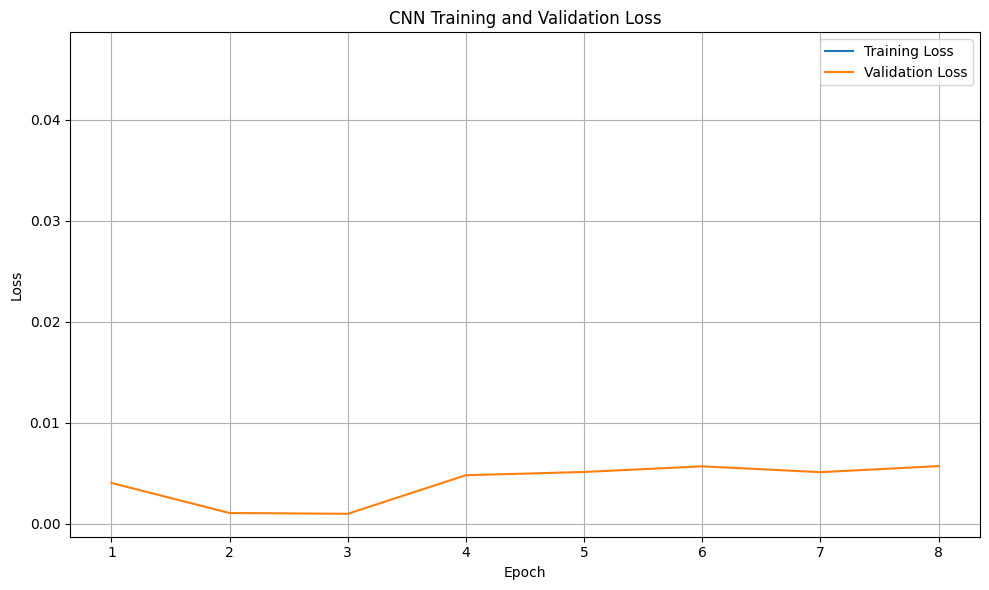

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(history["epoch"],history["train_loss"],label="Training Loss")
plt.plot(history["epoch"],history["val_loss"],label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
LOSS_PLOT = os.path.join(TRAINING_DIR,"training_loss_curve.png")
plt.savefig(LOSS_PLOT,dpi=300,bbox_inches="tight")
plt.show()

In [ ]:
### VALIDATION AUROC

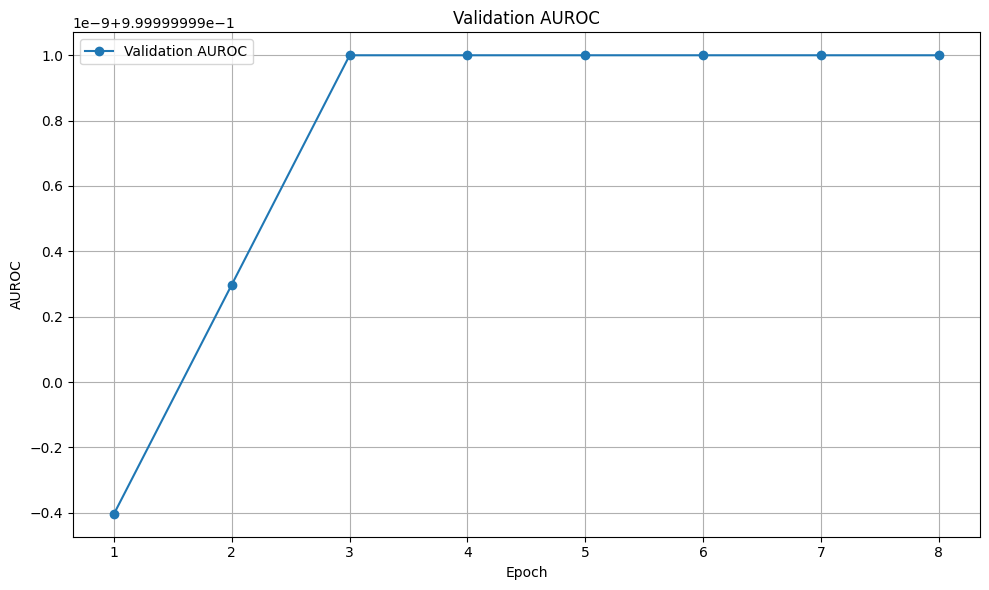

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(history["epoch"],history["val_auroc"],marker="o",label="Validation AUROC")
plt.xlabel("Epoch")
plt.ylabel("AUROC")
plt.title("Validation AUROC")
plt.grid(True)
plt.legend()
plt.tight_layout()
AUROC_PLOT = os.path.join(TRAINING_DIR,"validation_auroc_curve.png")
plt.savefig(AUROC_PLOT,dpi=300,bbox_inches="tight")
plt.show()

In [ ]:
### LEARNING RATE CURVES

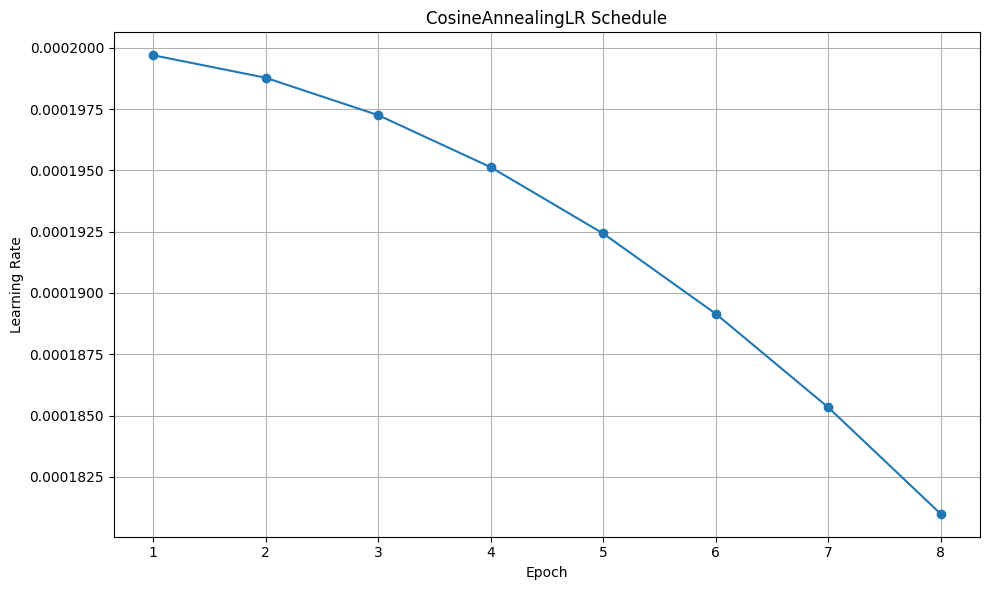

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(history["epoch"],history["learning_rate"],marker="o")
plt.xlabel("Epoch")
plt.ylabel("Learning Rate")
plt.title("CosineAnnealingLR Schedule")
plt.grid(True)
plt.tight_layout()
LR_PLOT = os.path.join(TRAINING_DIR,"learning_rate_curve.png")
plt.savefig(LR_PLOT,dpi=300,bbox_inches="tight")
plt.show()

In [ ]:
### RELOAD BEST MODEL

In [ ]:

assert os.path.exists(BEST_MODEL_PATH)

checkpoint = torch.load(BEST_MODEL_PATH,map_location=DEVICE,weights_only=False)

inference_model = StrainVisionNet(tabular_dim=5)
inference_model.load_state_dict(checkpoint["model_state_dict"])
inference_model = (inference_model.to(DEVICE))

inference_model.eval()

print("Best model loaded successfully.")
print("Best epoch:",checkpoint["epoch"])
print("Best validation AUROC:",checkpoint["metrics"].get("auroc"))

Best model loaded successfully.
Best epoch: 3
Best validation AUROC: 1.0


In [ ]:
### GENERIC INFERENCE FUNCTION

In [ ]:
def predict_dataset(model,loader,device):

    model.eval()

    all_targets = []
    all_probabilities = []

    with torch.no_grad():

        for ( spatial_x,tabular_x,targets) in loader:

            spatial_x = spatial_x.to(device,non_blocking=True)
            tabular_x = tabular_x.to(device,non_blocking=True)

            with torch.amp.autocast(
                device_type="cuda",enabled=(device.type == "cuda")):
                logits = model(spatial_x,tabular_x)

            probabilities = (torch.sigmoid(logits).squeeze(1).float().cpu().numpy())
            all_probabilities.append(probabilities)
            all_targets.append(targets.numpy())

    return (np.concatenate(all_targets),np.concatenate(all_probabilities))

In [ ]:
### VALIDATION PREDICTION

In [ ]:
val_targets, val_probabilities = (predict_dataset(inference_model,val_loader,DEVICE))

print("Validation predictions:",len(val_probabilities))

Validation predictions: 150000


In [ ]:
### STRICT 99% PRECISION THRESHOLD

In [ ]:
TARGET_PRECISION = 0.99


def find_precision_constrained_threshold(y_true,probabilities,target_precision=0.99):

    precision, recall, thresholds = (precision_recall_curve(y_true,probabilities))
    threshold_values = np.r_[thresholds,1.0]
    valid_indices = np.where(precision >= target_precision)[0]

    if len(valid_indices) == 0:

        raise RuntimeError(
            "No validation threshold "
            "achieved the requested "
            f"precision >= {target_precision:.2%}."
        )

    # Among thresholds meeting precision
    # requirement, maximize recall.
    best_index = valid_indices[np.argmax(recall[valid_indices])]
    threshold = threshold_values[best_index]

    return {
        "threshold": float(threshold),
        "precision": float( precision[best_index]),
        "recall": float(recall[best_index])}


threshold_result = (find_precision_constrained_threshold(val_targets,val_probabilities,TARGET_PRECISION))
OPERATING_THRESHOLD = (threshold_result["threshold"])

print("Validation threshold:",OPERATING_THRESHOLD)
print("Validation precision:",threshold_result["precision"])
print("Validation recall:",threshold_result["recall"])

Validation threshold: 0.2301025390625
Validation precision: 0.99
Validation recall: 1.0


In [ ]:
### PRECISION-RECALL CURVE

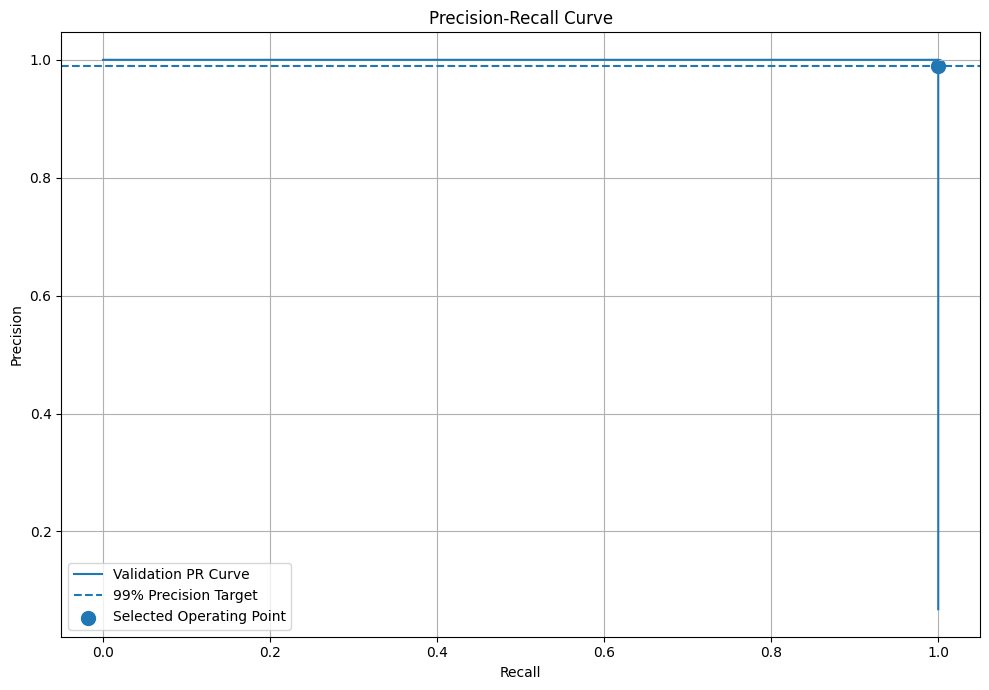

In [ ]:
precision, recall, thresholds = (precision_recall_curve(val_targets,val_probabilities))

plt.figure(figsize=(10, 7))
plt.plot(recall,precision,label="Validation PR Curve")
plt.axhline(TARGET_PRECISION,linestyle="--",label="99% Precision Target")
plt.scatter(threshold_result["recall"],threshold_result["precision"],s=100,
            label="Selected Operating Point")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.grid(True)
plt.legend()
plt.tight_layout()
PR_PLOT = os.path.join(EVALUATION_DIR,"precision_recall_curve.png")
plt.savefig(PR_PLOT,dpi=300,bbox_inches="tight")
plt.show()

In [ ]:
### ROC CURVE

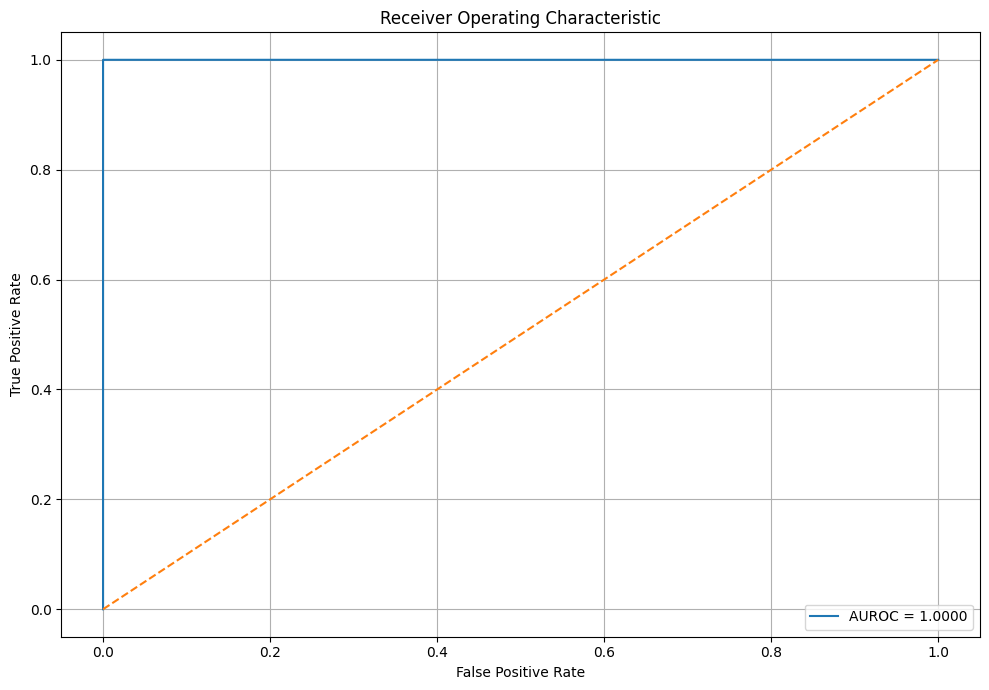

Validation AUROC: 1.000000


In [ ]:
fpr, tpr, roc_thresholds = (roc_curve(val_targets,val_probabilities))
val_auroc = roc_auc_score(val_targets,val_probabilities)

plt.figure(figsize=(10, 7))
plt.plot(fpr,tpr,label=f"AUROC = {val_auroc:.4f}")
plt.plot([0, 1],
         [0, 1],linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Receiver Operating Characteristic")
plt.grid(True)
plt.legend()
plt.tight_layout()
ROC_PLOT = os.path.join(EVALUATION_DIR,"roc_curve.png")
plt.savefig(ROC_PLOT,dpi=300,bbox_inches="tight")
plt.show()
print(f"Validation AUROC: {val_auroc:.6f}")

In [ ]:
### FINAL TEST EVALUTION

In [ ]:
test_targets, test_probabilities = (predict_dataset(inference_model,test_loader,DEVICE))
test_predictions = (test_probabilities >= OPERATING_THRESHOLD).astype(np.int64)
test_auroc = roc_auc_score(test_targets,test_probabilities)
test_precision = precision_score(test_targets,test_predictions,zero_division=0)

test_recall = recall_score(test_targets,test_predictions,zero_division=0)
test_f1 = f1_score(test_targets,test_predictions,zero_division=0)
test_accuracy = accuracy_score(test_targets,test_predictions)
test_ap = average_precision_score(test_targets,test_probabilities)

print("=" * 60)
print("FINAL UNSEEN TEST RESULTS")
print("=" * 60)

print(f"Threshold : {OPERATING_THRESHOLD:.6f}")
print(f"AUROC     : {test_auroc:.6f}")
print(f"AP        : {test_ap:.6f}")
print(f"Precision  : {test_precision:.6f}")
print(f"Recall     : {test_recall:.6f}")
print(f"F1         : {test_f1:.6f}")
print(f"Accuracy   : {test_accuracy:.6f}")

FINAL UNSEEN TEST RESULTS
Threshold : 0.230103
AUROC     : 1.000000
AP        : 1.000000
Precision  : 0.992118
Recall     : 1.000000
F1         : 0.996044
Accuracy   : 0.999460


In [ ]:
### CONFUSION MATRIX

In [ ]:

cm = confusion_matrix(test_targets,test_predictions)

tn, fp, fn, tp = cm.ravel()

print("Confusion Matrix")
print("----------------")
print(cm)

print()
print("True Negatives :", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives :", tp)

Confusion Matrix
----------------
[[139723     81]
 [     0  10196]]

True Negatives : 139723
False Positives: 81
False Negatives: 0
True Positives : 10196


In [ ]:
### CLASSIFICATION REPORT

In [ ]:
report = classification_report(test_targets,test_predictions,target_names=["Legitimate","Failure"],zero_division=0)

print(report)

report_path = os.path.join(EVALUATION_DIR,"classification_report.txt")
with open(report_path,"w") as file:
    file.write(report)

              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00    139804
     Failure       0.99      1.00      1.00     10196

    accuracy                           1.00    150000
   macro avg       1.00      1.00      1.00    150000
weighted avg       1.00      1.00      1.00    150000



In [ ]:
### SAVE CONFUSION MATRIX

In [ ]:
cm_df = pd.DataFrame(cm,index=["Actual_0","Actual_1"],columns=["Predicted_0","Predicted_1"])
cm_csv = os.path.join(EVALUATION_DIR,"confusion_matrix_metrics.csv")
cm_df.to_csv(cm_csv)

print("Saved:",cm_csv)

Saved: /content/drive/MyDrive/Nexlyra/11-09-26-Ravi/evaluation/confusion_matrix_metrics.csv


In [ ]:
### FALSE POSITIVE

In [ ]:
false_positive_mask = ((test_targets == 0) & (test_predictions == 1))
false_positive_indices = np.where(false_positive_mask)[0]

false_positive_df = pd.DataFrame({
    "Index":false_positive_indices,
    "True_Label":test_targets[false_positive_indices],
    "Probability":test_probabilities[false_positive_indices],
    "Prediction":test_predictions[false_positive_indices]})

FP_CSV = os.path.join(EVALUATION_DIR,"false_positives.csv")
false_positive_df.to_csv(FP_CSV,index=False)

print("False Positives:",len(false_positive_df))
print("Saved:",FP_CSV)

False Positives: 81
Saved: /content/drive/MyDrive/Nexlyra/11-09-26-Ravi/evaluation/false_positives.csv


In [ ]:
### FALSE POSITIVE STRUCTURAL ANALYSIS

In [ ]:
fp_indices = false_positive_indices
fp_features = (test_data["features"][fp_indices])

print("False Positive Analysis")
print("-" * 50)
print("Count:",len(fp_indices))

if len(fp_indices) > 0:

    print("Standardized Axial Load mean:",fp_features[:, 0].mean().item())
    print("Standardized Wind Shear mean:",fp_features[:, 1].mean().item())
    print("Symmetry_V mean:",fp_features[:, 2].mean().item())
    print("Symmetry_H mean:",fp_features[:, 3].mean().item())

    print("Center-to-Edge mean:",fp_features[:, 4].mean().item())

else:

    print("No false positives at the "
        "selected operating threshold.")

False Positive Analysis
--------------------------------------------------
Count: 81
Standardized Axial Load mean: 0.13455164432525635
Standardized Wind Shear mean: 0.3353126645088196
Symmetry_V mean: -0.49856793880462646
Symmetry_H mean: -0.051466137170791626
Center-to-Edge mean: 0.1287570595741272


In [ ]:
### HARD NEGATIVE MINING

In [ ]:
RECALL_TARGET = 0.90
test_fn_rate = (fn / max(fn + tp,1))

print(f"Test False Negative Rate: "f"{test_fn_rate:.4%}")

if test_recall < RECALL_TARGET:

    print("Recall below target.")
    print("Hard Negative Mining is eligible.")

else:
    print("Recall meets target.")
    print("Hard Negative Mining is not required.")

Test False Negative Rate: 0.0000%
Recall meets target.
Hard Negative Mining is not required.


In [ ]:
- For the actual hard-negative mining, i use the training dataset, not the test set

In [ ]:
def collect_hard_negatives(model,loader,device,threshold):

    model.eval()

    hard_negative_indices = []
    global_offset = 0

    with torch.no_grad():

        for (spatial_x,tabular_x,targets) in loader:

            batch_size = (spatial_x.size(0))
            spatial_x = spatial_x.to(device,non_blocking=True)
            tabular_x = tabular_x.to(device,non_blocking=True)

            with torch.amp.autocast(device_type="cuda",enabled=(device.type == "cuda")):

                logits = model(spatial_x,tabular_x)

            probabilities = (torch.sigmoid(logits).squeeze(1).cpu().numpy())
            targets_np = (targets.numpy())

            fp_mask = ((targets_np == 0) & (probabilities >= threshold))
            batch_indices = np.where(fp_mask)[0]

            hard_negative_indices.extend((global_offset + batch_indices).tolist())
            global_offset += batch_size

    return hard_negative_indices

In [ ]:

# DETERMINISTIC TRAINING LOADER
train_mining_loader = DataLoader(train_dataset,batch_size=BATCH_SIZE,shuffle=False,
                                num_workers=NUM_WORKERS,pin_memory=PIN_MEMORY,
                                persistent_workers=(NUM_WORKERS > 0))

In [ ]:

# MINE HARD NEGATIVES
hard_negative_indices = (collect_hard_negatives(inference_model,train_mining_loader,
                                                DEVICE,OPERATING_THRESHOLD))

print("Hard negatives found:",len(hard_negative_indices))

Hard negatives found: 661


In [ ]:
if len(hard_negative_indices) > 0:

    hard_indices_tensor = torch.tensor(hard_negative_indices,dtype=torch.long)

    hard_negative_data = {
        "strain":train_data["strain"][hard_indices_tensor],
        "features":train_data["features"][hard_indices_tensor],
        "target":train_data["target"][hard_indices_tensor]}

    hard_negative_dataset = (StrainVisionDataset(hard_negative_data))

    hard_negative_loader = DataLoader(hard_negative_dataset,
                                      batch_size=BATCH_SIZE,
                                      shuffle=True,
                                      num_workers=NUM_WORKERS,
                                      pin_memory=PIN_MEMORY,
                                      persistent_workers=(
                                      NUM_WORKERS > 0))

    print("Hard-negative dataset:",len(hard_negative_dataset))

else:

    hard_negative_loader = None

    print("No hard negatives available.")

Hard-negative dataset: 661


In [ ]:
### EXTRACT TEXT EMBEDDINGS

In [ ]:
print(inference_model)

StrainVisionNet(
  (spatial_branch): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): LeakyReLU(negative_slope=0.01, inplace=True)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Flatten(start_dim=1, end_dim=-1)
  )
  (tabular_branch): Sequential(
    (0): Linear(in_features=5, out_features=64, bias=True)
    (1): ReLU(inplace=True)
    (2): Dropout(p=0.4, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU(inplace=True)
    (5): Dropout(p=0.4, inplace=False)
  )
  (fusion): Sequential(
    (0): Linear(in_features=1056, out_features=128, bias=True)
    (1): ReLU(inplace=True)
    (2): Dropout(p=0.4, inplace=False)
    (3): Linear(in_features=128, out_features=1, bias=True)
  )
)


In [ ]:
UMAP_SAMPLES = min(30000, len(test_data["target"]))

# Reproducible sampling
torch.manual_seed(42)

umap_indices = torch.randperm(len(test_data["target"]))[:UMAP_SAMPLES]

umap_spatial = test_data["strain"][umap_indices]
umap_features = test_data["features"][umap_indices]
umap_targets = test_data["target"][umap_indices]

embedding_batches = []

# Use the trained best model
inference_model.eval()

with torch.no_grad():

    for start in range(0, UMAP_SAMPLES, BATCH_SIZE):

        end = min(start + BATCH_SIZE, UMAP_SAMPLES)
        spatial_x = (umap_spatial[start:end].to(DEVICE, non_blocking=True))
        tabular_x = (umap_features[start:end].to(DEVICE, non_blocking=True))

        with torch.amp.autocast(device_type="cuda",enabled=AMP_ENABLED):

            # Spatial branch: 8x8 strain matrix -> 1024 features
            spatial_features = inference_model.spatial_branch(spatial_x)

            # Tabular branch: 5 features -> 32 features
            tabular_features = inference_model.tabular_branch(tabular_x)

            # Concatenate spatial + tabular representations
            fused_features = torch.cat([spatial_features, tabular_features],dim=1)

            # Fusion layer: 1056 -> 128
            embedding = inference_model.fusion[0](fused_features)

            # ReLU
            embedding = inference_model.fusion[1](embedding)

        embedding_batches.append(embedding.float().cpu())

# Combine all batches
embeddings = torch.cat(embedding_batches,dim=0).numpy()
umap_targets = umap_targets.cpu().numpy()

print("Embedding shape:", embeddings.shape)
print("Target shape:", umap_targets.shape)



Embedding shape: (30000, 128)
Target shape: (30000,)


In [ ]:
### INSTALL UMAP

In [ ]:
!pip uninstall -y umap-learn numba llvmlite
!pip install --no-cache-dir --force-reinstall \
    "numba==0.63.1" \
    "llvmlite==0.46.0" \
    "umap-learn==0.5.9.post2"

Found existing installation: umap-learn 0.5.9.post2
Uninstalling umap-learn-0.5.9.post2:
  Successfully uninstalled umap-learn-0.5.9.post2
Found existing installation: numba 0.63.1
Uninstalling numba-0.63.1:
  Successfully uninstalled numba-0.63.1
Found existing installation: llvmlite 0.46.0
Uninstalling llvmlite-0.46.0:
  Successfully uninstalled llvmlite-0.46.0
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.1/62.1 kB 31.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 198.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.4/57.4 kB 173.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 15.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 26.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.1/90.1 kB 184.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.6/16.6 MB 18.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.5/73.5 kB 205.9 MB/s eta 0:00

In [ ]:
import numba
import umap

print("Numba:", numba.__version__)
print("UMAP:", umap.__version__)

Numba: 0.63.1
UMAP: 0.5.9.post2


In [ ]:
import umap

reducer = umap.UMAP(n_components=2, n_neighbors=15,
                    min_dist=0.1,metric="euclidean",random_state=RANDOM_STATE)

embedding_2d = reducer.fit_transform(embeddings)
print("UMAP shape:",embedding_2d.shape)

UMAP shape: (30000, 2)


In [ ]:
### UMAP BY TARGET

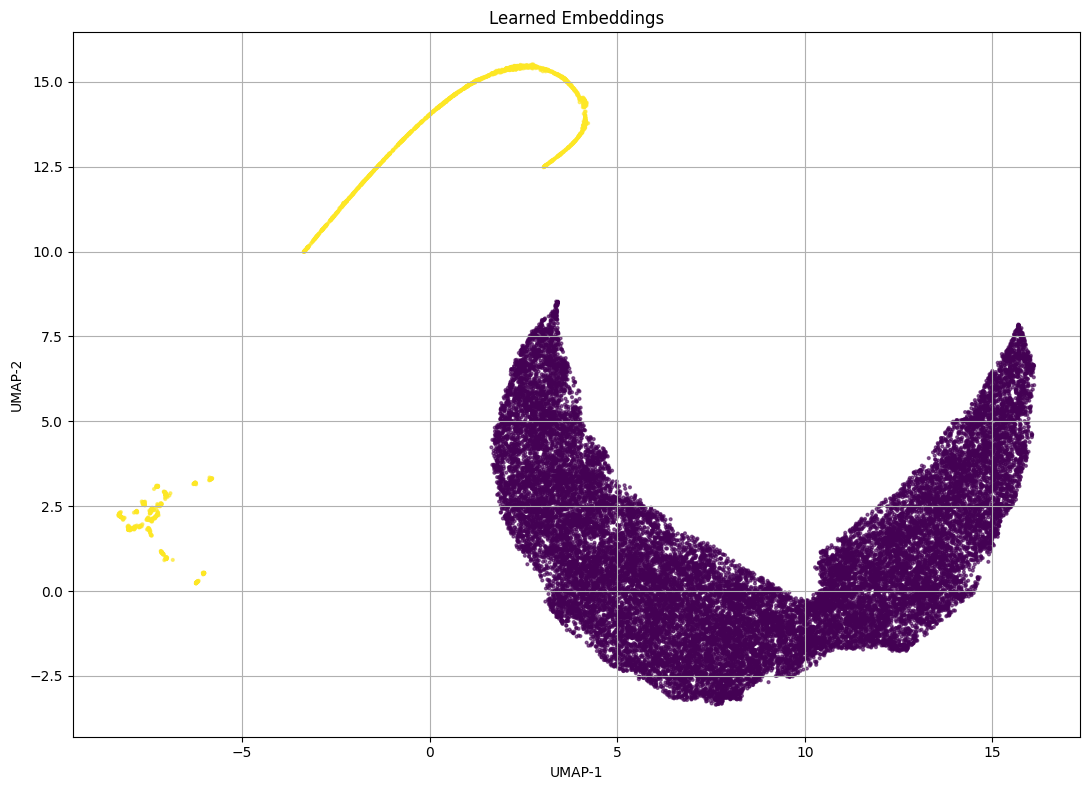

In [ ]:
plt.figure(figsize=(11, 8))

scatter = plt.scatter(embedding_2d[:, 0],embedding_2d[:, 1],
                      c=umap_targets,s=4,alpha=0.6)
plt.xlabel("UMAP-1")
plt.ylabel("UMAP-2")
plt.title("Learned Embeddings")
plt.grid(True)
plt.tight_layout()
UMAP_TARGET_PLOT = os.path.join( EVALUATION_DIR,"umap_target.png")
plt.savefig(UMAP_TARGET_PLOT,dpi=300,bbox_inches="tight")
plt.show()

In [ ]:
# LOAD VENDOR METADATA
VENDOR_METADATA_PATH = os.path.join(TENSOR_DIR,"vendor_metadata.pt")
vendor_metadata = torch.load(VENDOR_METADATA_PATH,weights_only=False)

print("Vendor metadata loaded.")
print("Type:", type(vendor_metadata))

if isinstance(vendor_metadata, dict):
    print("Keys:", vendor_metadata.keys())

Vendor metadata loaded.
Type: <class 'dict'>
Keys: dict_keys(['train_vendor', 'val_vendor', 'test_vendor'])


In [ ]:
train_vendor = vendor_metadata["train_vendor"]
val_vendor = vendor_metadata["val_vendor"]
test_vendor = vendor_metadata["test_vendor"]

print("Train vendors:", len(train_vendor))
print("Val vendors  :", len(val_vendor))
print("Test vendors :", len(test_vendor))

assert len(test_vendor) == len(test_data["target"])

print("PASS: Test Vendor metadata is aligned with test tensor.")

Train vendors: 700000
Val vendors  : 150000
Test vendors : 150000
PASS: Test Vendor metadata is aligned with test tensor.


In [ ]:
## Think

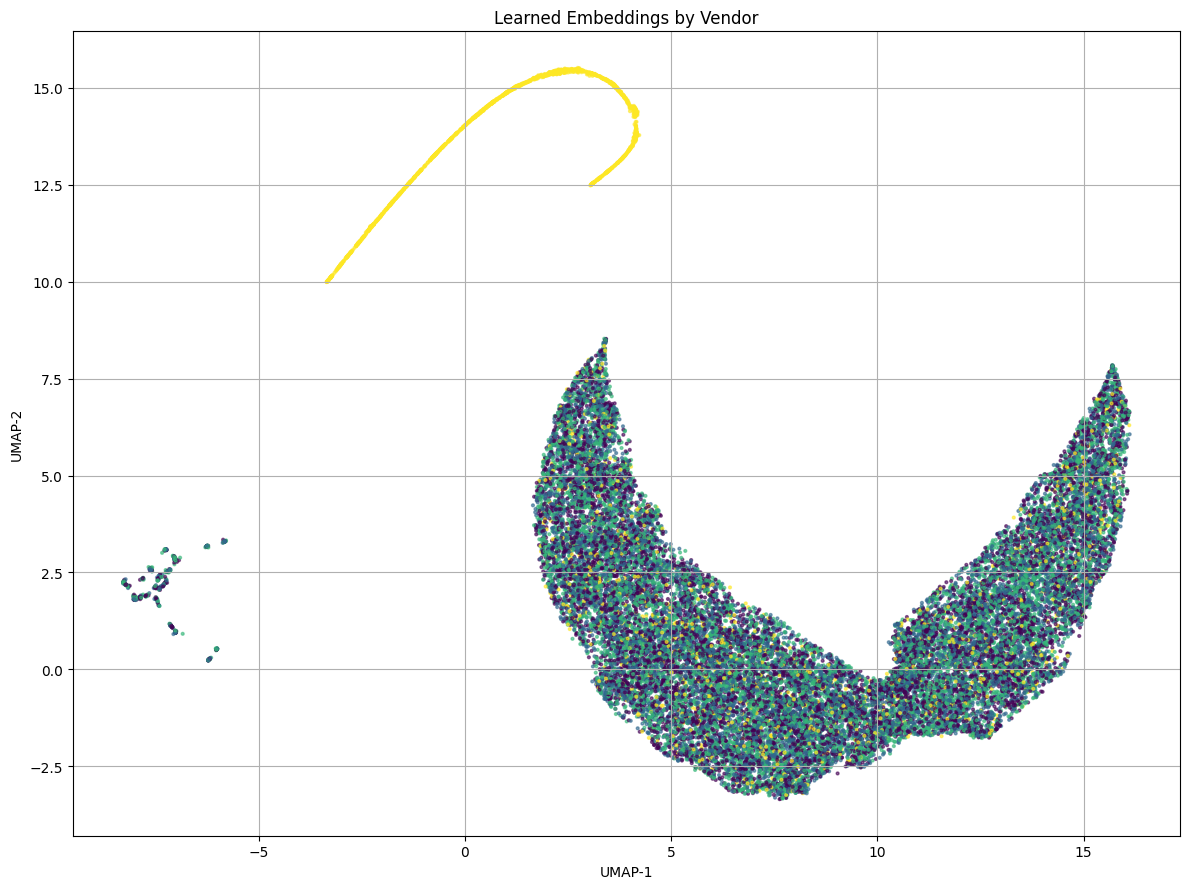

In [ ]:
# VENDOR UMAP
if "test_vendor" in globals():

    vendor_subset = [test_vendor[i] for i in umap_indices.tolist()]
    vendor_series = pd.Series(vendor_subset)
    vendor_codes = (vendor_series.astype("category").cat.codes.to_numpy())

    plt.figure(figsize=(12, 9))
    plt.scatter(embedding_2d[:, 0],embedding_2d[:, 1],c=vendor_codes,s=4,alpha=0.6)
    plt.xlabel("UMAP-1")
    plt.ylabel("UMAP-2")
    plt.title("Learned Embeddings by Vendor")
    plt.grid(True)
    plt.tight_layout()

    UMAP_VENDOR_PLOT = os.path.join(EVALUATION_DIR,"umap_vendor.png")

    plt.savefig(UMAP_VENDOR_PLOT,dpi=300,bbox_inches="tight")
    plt.show()

else:

    print(
        "Vendor-aligned test labels are "
        "not available."
    )

In [ ]:
### EXPECTED CALIBERATION ERROR

In [ ]:
def expected_calibration_error(y_true,probabilities, n_bins=10):
    y_true = np.asarray(y_true)
    probabilities = np.asarray(probabilities)
    bin_edges = np.linspace( 0.0,1.0,n_bins + 1)

    ece = 0.0
    bin_results = []

    for i in range(n_bins):

        lower = bin_edges[i]
        upper = bin_edges[i + 1]

        if i == n_bins - 1:
            mask = ((probabilities >= lower) & (probabilities <= upper))
        else:

            mask = ((probabilities >= lower) & (probabilities < upper))

        if not np.any(mask):
            continue

        confidence = (probabilities[mask].mean())
        accuracy = ( y_true[mask].mean())
        fraction = (mask.mean())

        ece += (fraction * abs(accuracy - confidence))
        bin_results.append({
            "bin": i,
            "confidence": confidence,
            "accuracy": accuracy,
            "fraction": fraction
        })

    return ece, pd.DataFrame(bin_results)


ece, calibration_bins = (expected_calibration_error(test_targets,test_probabilities,
                                                    n_bins=10))
print( f"Test ECE: {ece:.6f}")

Test ECE: 0.061916


In [ ]:
### RELIABILITY DIAGRAM

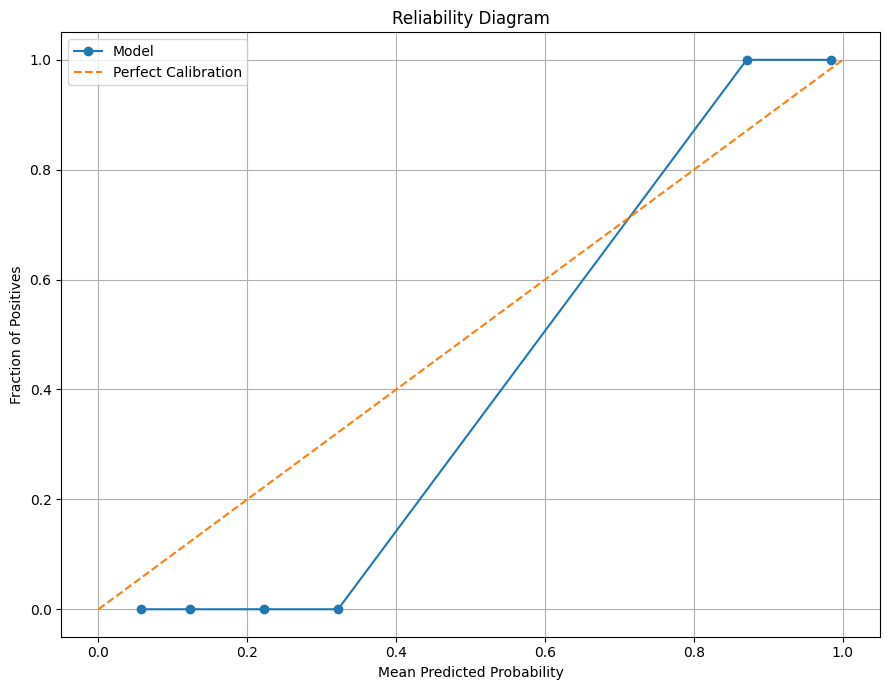

In [ ]:
fraction_of_positives, mean_predicted_value = (calibration_curve(test_targets,test_probabilities,
                                                                 n_bins=10,strategy="uniform"))
plt.figure(figsize=(9, 7))

plt.plot(mean_predicted_value,fraction_of_positives,marker="o",label="Model")
plt.plot([0, 1],[0, 1],
    linestyle="--",
    label="Perfect Calibration")
plt.xlabel("Mean Predicted Probability")
plt.ylabel("Fraction of Positives")
plt.title("Reliability Diagram")
plt.grid(True)
plt.legend()
plt.tight_layout()

CALIBRATION_PLOT = os.path.join(EVALUATION_DIR,"calibration_curve.png")
plt.savefig(CALIBRATION_PLOT,dpi=300,bbox_inches="tight")
plt.show()

In [ ]:
### TEMPERATURE SCALING

In [ ]:
class TemperatureScaler(nn.Module):

    def __init__(self,initial_temperature=1.0):

        super().__init__()

        self.temperature = nn.Parameter(torch.tensor([initial_temperature],
                                                     dtype=torch.float32))

    def forward(self,logits):
        temperature = torch.clamp(self.temperature, min=0.05,max=10.0)
        return (logits / temperature)

In [ ]:
# VALIDATION LOGITs

def collect_logits(model,loader,device):

    model.eval()

    logits_list = []
    targets_list = []

    with torch.no_grad():

        for (spatial_x,tabular_x,targets) in loader:
            spatial_x = spatial_x.to(device,non_blocking=True)
            tabular_x = tabular_x.to(device,non_blocking=True)

            with torch.amp.autocast(device_type="cuda",enabled=AMP_ENABLED):

                logits = model(spatial_x,tabular_x)

            logits_list.append(logits.float().cpu())
            targets_list.append(targets.float().cpu())

    return (torch.cat( logits_list).squeeze(1),torch.cat(targets_list))


val_logits, val_targets_tensor = (collect_logits(inference_model,val_loader,DEVICE))
print("Validation logits:",val_logits.shape)

Validation logits: torch.Size([150000])


In [ ]:
# FIT TEMPERATURE

temperature_scaler = (TemperatureScaler())
temperature_optimizer = torch.optim.LBFGS(temperature_scaler.parameters(),
                                          lr=0.01,max_iter=100)
temperature_criterion = (nn.BCEWithLogitsLoss())
val_logits_for_temperature = (val_logits)
val_targets_for_temperature = (val_targets_tensor)


def temperature_closure():

    temperature_optimizer.zero_grad()
    scaled_logits = (temperature_scaler(val_logits_for_temperature))
    loss = temperature_criterion(scaled_logits,val_targets_for_temperature)

    loss.backward()

    return loss


temperature_optimizer.step( temperature_closure)
learned_temperature = (temperature_scaler.temperature.detach().item())

print("Learned temperature:",learned_temperature)

Learned temperature: 0.5126327872276306


In [ ]:
### STRUCTURAL RISK SCORE

In [ ]:
FN_PENALTY = 1000.0
FP_PENALTY = 1.0
TP_PENALTY = 0.0
TN_PENALTY = 0.0


def structural_risk_score(y_true,y_pred,
                          fn_penalty=1000.0,fp_penalty=1.0,
                          tp_penalty=0.0,tn_penalty=0.0):

    cm = confusion_matrix( y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()

    risk = (tn * tn_penalty +
            fp * fp_penalty +
            fn * fn_penalty +
            tp * tp_penalty)

    return {
        "risk_score": float(risk),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp)
    }

In [ ]:
### ML RISK VS NAIVE BASELINE

In [ ]:
wind_mean = 42.57220636
wind_scale = 24.35149790

test_wind_mph = (test_data["features"][:, 1].numpy() * wind_scale + wind_mean)
naive_predictions = (test_wind_mph > 60.0).astype(np.int64)

ml_risk = structural_risk_score(test_targets,
                                test_predictions,
                                fn_penalty=FN_PENALTY,
                                fp_penalty=FP_PENALTY)

naive_risk = structural_risk_score(test_targets,
                                   naive_predictions,
                                   fn_penalty=FN_PENALTY,
                                   fp_penalty=FP_PENALTY)

print("=" * 60)
print("STRUCTURAL RISK COMPARISON")
print("=" * 60)

print("ML Risk:",ml_risk["risk_score"])
print("Naive Risk:",naive_risk["risk_score"])

risk_reduction = (1.0 -(ml_risk["risk_score"] /max(naive_risk["risk_score"],1e-12)))

print(f"Risk reduction: "
      f"{risk_reduction:.2%}")

STRUCTURAL RISK COMPARISON
ML Risk: 81.0
Naive Risk: 35099.0
Risk reduction: 99.77%


In [ ]:
### SENSITIVE ANALYSIS - WIND CORRUPTION

In [ ]:
NOISE_LOW = -0.25
NOISE_HIGH = 0.25

corrupted_features = (test_data["features"].clone())
wind_noise = (torch.empty(len(corrupted_features)).uniform_(NOISE_LOW,NOISE_HIGH))
corrupted_features[:, 1] += (wind_noise)

corrupted_test_data = {
    "strain":test_data["strain"],
    "features":corrupted_features,
    "target":test_data["target"]
}

corrupted_test_dataset = (StrainVisionDataset(corrupted_test_data))

corrupted_test_loader = DataLoader(corrupted_test_dataset,batch_size=BATCH_SIZE,
                                    shuffle=False,num_workers=NUM_WORKERS,
                                    pin_memory=PIN_MEMORY,persistent_workers=(
                                    NUM_WORKERS > 0))

_, corrupted_probabilities = (predict_dataset(inference_model,corrupted_test_loader, DEVICE))

corrupted_auroc = roc_auc_score(test_targets,corrupted_probabilities)

print(f"Original AUROC   : {test_auroc:.6f}")
print(f"Corrupted AUROC  : {corrupted_auroc:.6f}")
print(f"AUROC drop       : "
    f"{test_auroc - corrupted_auroc:.6f}")

Original AUROC   : 1.000000
Corrupted AUROC  : 1.000000
AUROC drop       : 0.000000


In [ ]:
### HORIZONTAL SPATIAL FLIP

In [ ]:
flipped_strain = torch.flip(test_data["strain"],dims=[3])
flipped_test_data = {
    "strain":flipped_strain,
    "features":test_data["features"],
    "target":test_data["target"]}

flipped_dataset = (StrainVisionDataset(flipped_test_data))

flipped_loader = DataLoader(flipped_dataset,batch_size=BATCH_SIZE,
                            shuffle=False,num_workers=NUM_WORKERS,
                            pin_memory=PIN_MEMORY, persistent_workers=(
                            NUM_WORKERS > 0))

_, flipped_probabilities = (predict_dataset(inference_model,flipped_loader,DEVICE))
flipped_predictions = (flipped_probabilities >= OPERATING_THRESHOLD).astype(np.int64)
flipped_auroc = roc_auc_score(test_targets,flipped_probabilities)
flipped_f1 = f1_score(test_targets,flipped_predictions,zero_division=0)

print(f"Original AUROC : {test_auroc:.6f}")
print(f"Flipped AUROC  : {flipped_auroc:.6f}")
print(f"AUROC change   : "
    f"{flipped_auroc - test_auroc:.6f}")
print(f"Original F1    : {test_f1:.6f}")
print(f"Flipped F1     : {flipped_f1:.6f}")

Original AUROC : 1.000000
Flipped AUROC  : 0.000205
AUROC change   : -0.999795
Original F1    : 0.996044
Flipped F1     : 0.127294


In [ ]:
### HIGHEST PRABABILITY TRUE POSITIVE

In [ ]:
true_positive_indices = np.where((test_targets == 1) &(test_predictions == 1))[0]

if len(true_positive_indices) > 0:
    highest_tp_index = (true_positive_indices[np.argmax(test_probabilities[ true_positive_indices])])

    print("Highest-probability True Positive")
    print("Index:",highest_tp_index)
    print("Probability:",test_probabilities[ highest_tp_index])

else:

    highest_tp_index = None

    print("No True Positives at "
        "the operating threshold.")

Highest-probability True Positive
Index: 7362
Probability: 0.9995117


In [ ]:
### LOWEST PROBABILITY FALSE NEGATIVE

In [ ]:

false_negative_indices = np.where((test_targets == 1) & (test_predictions == 0))[0]

if len(false_negative_indices) > 0:
    lowest_fn_index = (false_negative_indices[np.argmin(test_probabilities[false_negative_indices])])

    print("Lowest-probability False Negative")
    print("Index:",lowest_fn_index)
    print("Probability:",test_probabilities[lowest_fn_index])

else:

    lowest_fn_index = None

    print("No False Negatives.")

No False Negatives.


In [ ]:
### FALSE NEGATIVE MATRIX ANALYSIS

In [ ]:
print("lowest_fn_index:", lowest_fn_index)

lowest_fn_index: None


In [ ]:
if lowest_fn_index is not None:

    fn_matrix = (test_data["strain"][lowest_fn_index].squeeze(0).numpy())

    print("False Negative Matrix")
    print("Minimum:",fn_matrix.min())
    print("Maximum:",fn_matrix.max())
    print("Mean:",fn_matrix.mean())
    print("Variance:",fn_matrix.var())

    plt.figure(figsize=(7, 6))
    plt.imshow(fn_matrix,aspect="auto")
    plt.colorbar(label="Strain")
    plt.title("Lowest-Probability False Negative")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.tight_layout()

    FN_MATRIX_PLOT = os.path.join(EVALUATION_DIR,"lowest_probability_false_negative.png")

    plt.savefig(FN_MATRIX_PLOT,dpi=300,bbox_inches="tight")
    plt.show()

else :
  print("No False Negative Index Exist")

No False Negative Index Exist


In [ ]:
### SAVE FINAL MATRIX

In [ ]:
final_metrics = {

    "operating_threshold":float(OPERATING_THRESHOLD),
    "target_validation_precision":float(TARGET_PRECISION),
    "validation_precision_at_threshold":float(threshold_result["precision"]),
    "validation_recall_at_threshold":float(threshold_result["recall"]),
    "test_auroc": float(test_auroc),
    "test_average_precision":float(test_ap),
    "test_precision":float(test_precision),
    "test_recall":float(test_recall),
    "test_f1":float(test_f1),
    "test_accuracy":float(test_accuracy),
    "true_negatives":int(tn),
    "false_positives":int(fp),
    "false_negatives":int(fn),
    "true_positives":int(tp),
    "test_ece":float(ece),
    "temperature":float(learned_temperature),
    "wind_corrupted_auroc":float(corrupted_auroc),
    "wind_auroc_drop":float(test_auroc - corrupted_auroc ),
    "flipped_auroc":float(flipped_auroc),
    "flipped_f1":float(flipped_f1),
    "risk_ml":float(ml_risk["risk_score"]),
    "risk_naive":float(naive_risk["risk_score"])}

METRICS_JSON = os.path.join( EVALUATION_DIR,"final_metrics.json")

with open(METRICS_JSON,"w") as file:

    json.dump(final_metrics,file,indent=4)

print("Saved:",METRICS_JSON)

Saved: /content/drive/MyDrive/Nexlyra/11-09-26-Ravi/evaluation/final_metrics.json


In [ ]:
### SAVE FINAL THRESHOLD COFIGURATION

In [ ]:

production_config = {

    "project":"Strain Matrix",

    "model":"StrainVisionNet",

    "input_shapes": {"spatial": ["B", 1, 8, 8],
        "tabular": ["B",5]},

    "output":"single_logit",

    "sigmoid_in_model":False,

    "operating_threshold":float(OPERATING_THRESHOLD),

    "threshold_selection":"Validation threshold maximizing recall subject to validation precision >= 99%",

    "target_precision":0.99,

    "batch_size":BATCH_SIZE,

    "learning_rate":LEARNING_RATE,

    "weight_decay":WEIGHT_DECAY,

    "epochs":EPOCHS,

    "optimizer":"AdamW",

    "scheduler":"CosineAnnealingLR",

    "amp":AMP_ENABLED,

    "mixup_alpha":0.2,

    "mixup_probability":0.5,

    "gradient_clip_norm":1.0,

    "loss":
        {
            "name":"AsymmetricFocalLoss",
            "alpha_neg":2.0,
            "alpha_pos":1.0,
            "gamma_neg":2.0,
            "gamma_pos":1.0
        },

    "random_state":RANDOM_STATE
}

CONFIG_JSON = os.path.join(MODEL_DIR,"model_config.json")

with open(CONFIG_JSON,"w") as file:

    json.dump(production_config,file, indent=4)

print("Production configuration saved:")

print(CONFIG_JSON)

Production configuration saved:
/content/drive/MyDrive/Nexlyra/11-09-26-Ravi/models/model_config.json


In [ ]:
### PRODUCTION MODEL DOCSTRING

In [ ]:


FINAL_MODEL_DOCUMENTATION = f"""
NEXLYRA STRAINVISIONNET — PRODUCTION CONFIGURATION
===================================================

Model:StrainVisionNet

Spatial Input:[B, 1, 8, 8]

Tabular Input:[B, 5]

Output:Single raw logit.

Sigmoid:
    NOT applied inside forward().
    Sigmoid is applied only during inference
    for probability generation.

Training:
    Epoch budget: {EPOCHS}
    Batch size: {BATCH_SIZE}

Optimizer: AdamW

Learning Rate:{LEARNING_RATE}

Weight Decay:{WEIGHT_DECAY}

Scheduler:CosineAnnealingLR

Mixed Precision:{AMP_ENABLED}

MixUp:
    Alpha = 0.2
    Probability = 0.5

Gradient Clipping:
    Maximum norm = 1.0

Loss:
    AsymmetricFocalLoss

    alpha_neg = 2.0
    alpha_pos = 1.0
    gamma_neg = 2.0
    gamma_pos = 1.0

Operational Threshold:
    {OPERATING_THRESHOLD:.8f}

Threshold Selection:
    The threshold was selected on the validation
    dataset to achieve at least 99% validation
    precision while maximizing validation recall.

IMPORTANT:
    The 99% precision constraint is a validation-set
    operating criterion, NOT a mathematical guarantee
    of 99% precision on unseen production data.

Test Metrics:
    AUROC = {test_auroc:.6f}
    Precision = {test_precision:.6f}
    Recall = {test_recall:.6f}
    F1 = {test_f1:.6f}

Calibration:
    ECE = {ece:.6f}
    Learned temperature = {learned_temperature:.6f}

Risk:
    False Negative penalty = {FN_PENALTY}
    False Positive penalty = {FP_PENALTY}

Random State:
    {RANDOM_STATE}
"""

DOCUMENTATION_PATH = os.path.join(MODEL_DIR,"production_model_documentation.txt")

with open(DOCUMENTATION_PATH,"w") as file:

    file.write(FINAL_MODEL_DOCUMENTATION)

print("Documentation saved:")
print(DOCUMENTATION_PATH)

Documentation saved:
/content/drive/MyDrive/Nexlyra/11-09-26-Ravi/models/production_model_documentation.txt


In [ ]:
### SECURE BACKUP OF BEST MODEL

In [ ]:

BACKUP_MODEL_PATH = os.path.join(BACKUP_DIR,"best_model.pth")

shutil.copy2(BEST_MODEL_PATH,BACKUP_MODEL_PATH)

print("Primary model:")
print(BEST_MODEL_PATH)
print("\nBackup model:")
print(BACKUP_MODEL_PATH)

assert os.path.exists(BACKUP_MODEL_PATH)

print("\nPASS: Best model backup exists.")

Primary model:
/content/drive/MyDrive/Nexlyra/11-09-26-Ravi/models/best_model.pth

Backup model:
/content/drive/MyDrive/Nexlyra/11-09-26-Ravi/backup/best_model.pth

PASS: Best model backup exists.


In [ ]:
### GRADE CAM ENVIROMENT

In [ ]:
!pip -q install grad-cam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 2.6 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
# GRAD-CAM IMPORT TEST


try:

    from pytorch_grad_cam import (GradCAM)
    from pytorch_grad_cam.utils.model_targets import (BinaryClassifierOutputTarget)
    from pytorch_grad_cam.utils.image import (show_cam_on_image)

    print("Grad-CAM environment: READY")

except Exception as error:

    print("Grad-CAM environment error:")
    print(error)

Grad-CAM environment: READY


In [ ]:
### PRODUCTION ARTIFACT INVENTORY

In [ ]:
print("=" * 70)
print("PRODUCTION ARTIFACTS")
print("=" * 70)

artifact_paths = [BEST_MODEL_PATH,
                  BACKUP_MODEL_PATH,
                  CONFIG_JSON,
                 DOCUMENTATION_PATH,
                 METRICS_JSON,
                 HISTORY_CSV,
                LOSS_PLOT,
                AUROC_PLOT,
                LR_PLOT,
                PR_PLOT,
                ROC_PLOT,
                CALIBRATION_PLOT,
                cm_csv,
               report_path]

for path in artifact_paths:

    status = ("OK" if os.path.exists(path) else "MISSING")
    print(f"{status:8} {path}")

PRODUCTION ARTIFACTS
OK       /content/drive/MyDrive/Nexlyra/11-09-26-Ravi/models/best_model.pth
OK       /content/drive/MyDrive/Nexlyra/11-09-26-Ravi/backup/best_model.pth
OK       /content/drive/MyDrive/Nexlyra/11-09-26-Ravi/models/model_config.json
OK       /content/drive/MyDrive/Nexlyra/11-09-26-Ravi/models/production_model_documentation.txt
OK       /content/drive/MyDrive/Nexlyra/11-09-26-Ravi/evaluation/final_metrics.json
OK       /content/drive/MyDrive/Nexlyra/11-09-26-Ravi/training/training_history.csv
OK       /content/drive/MyDrive/Nexlyra/11-09-26-Ravi/training/training_loss_curve.png
OK       /content/drive/MyDrive/Nexlyra/11-09-26-Ravi/training/validation_auroc_curve.png
OK       /content/drive/MyDrive/Nexlyra/11-09-26-Ravi/training/learning_rate_curve.png
OK       /content/drive/MyDrive/Nexlyra/11-09-26-Ravi/evaluation/precision_recall_curve.png
OK       /content/drive/MyDrive/Nexlyra/11-09-26-Ravi/evaluation/roc_curve.png
OK       /content/drive/MyDrive/Nexlyra/11-09-26-

In [ ]:
### FINAL PRODUCTION SMOKE TEST

In [ ]:
inference_model.eval()

sample_spatial = (test_data["strain"][:4].to(DEVICE))
sample_features = (test_data["features"][:4].to(DEVICE))

with torch.no_grad():

    with torch.amp.autocast( device_type="cuda",enabled=AMP_ENABLED):

        sample_logits = (inference_model(sample_spatial,sample_features))

sample_probabilities = (torch.sigmoid(sample_logits))

assert sample_logits.shape == (4, 1)
assert torch.isfinite(sample_logits).all()
assert torch.isfinite(sample_probabilities).all()
assert (sample_probabilities >= 0).all()
assert (sample_probabilities <= 1).all()

print("=" * 60)
print("PRODUCTION SMOKE TEST")
print("=" * 60)
print("Input spatial:",sample_spatial.shape)
print("Input features:",sample_features.shape)
print("Output logits:",sample_logits.shape)
print("Probabilities:",sample_probabilities.squeeze(1).detach().cpu().numpy())
print("\nPASS: Production inference path verified.")